# Model Diagnostics

## 1. Introduction

This notebook evaluates the assumptions and reliability of the selected Nonlinear TV + Interaction Regression Model.

Although the model achieved strong performance during cross-validation and statistical testing, a high R-squared value alone does not guarantee that the regression model is appropriate.

The following diagnostic checks will be performed:

1. **Normality of Residuals:** Examine whether the residuals approximately follow a normal distribution.
2. **Homoscedasticity:** Check whether the residual variance remains approximately constant across predicted values.
3. **Multicollinearity:** Review the relationships among model predictors.
4. **Influential Observations:** Identify observations that may disproportionately influence the fitted model.

These checks will help assess the reliability of the model and identify potential limitations before final evaluation on the test dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.utils import load_and_split

df_train, df_test = load_and_split(
    path=PROJECT_ROOT / "Dataset" / "Advertising.csv"
)

df = df_train.copy()

# Feature engineering
df["sqrt_tv"] = np.sqrt(df["tv"])
df["sqrt_tv_c"] = df["sqrt_tv"] - df["sqrt_tv"].mean()
df["radio_c"] = df["radio"] - df["radio"].mean()

# Fit selected model
model_d = smf.ols(
    "sales ~ sqrt_tv_c * radio_c",
    data=df
).fit()

# Predictions and residuals
df["predicted_sales"] = model_d.fittedvalues
df["residuals"] = model_d.resid

print(model_d.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     6600.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          4.56e-164
Time:                        14:27:24   Log-Likelihood:                -99.372
No. Observations:                 160   AIC:                             206.7
Df Residuals:                     156   BIC:                             219.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            14.0561      0.03

## 2. Normality of Residuals

Residuals represent the differences between actual and predicted Sales.

For conventional OLS statistical inference, the residuals are commonly assessed for approximate normality.

We will examine the residual distribution using:

- Histogram with a KDE curve
- Q-Q plot
- Shapiro-Wilk test

The Shapiro-Wilk test evaluates the following hypotheses:

- H₀: The residuals follow a normal distribution.
- H₁: The residuals do not follow a normal distribution.

A p-value below 0.05 provides evidence against normality.

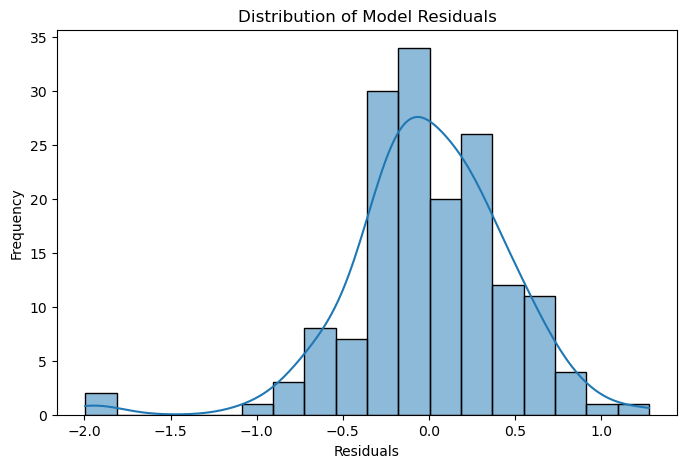

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["residuals"],
    kde=True
)

plt.title("Distribution of Model Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

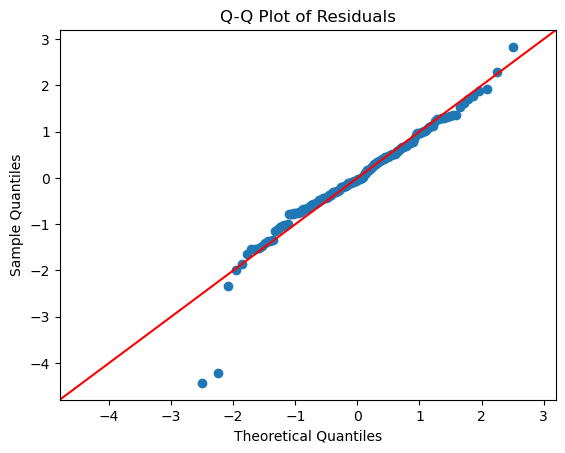

In [4]:
sm.qqplot(
    df["residuals"],
    line="45",
    fit=True
)

plt.title("Q-Q Plot of Residuals")
plt.show()

In [5]:
shapiro_stat, shapiro_p = stats.shapiro(df["residuals"])

print("Shapiro-Wilk Statistic:", shapiro_stat)
print("P-value:", shapiro_p)

Shapiro-Wilk Statistic: 0.9523244509076275
P-value: 2.8692977545969948e-05


### Shapiro-Wilk Test — Key Findings

1. The Shapiro-Wilk test produced a statistic of 0.9523 and a p-value of 0.00002869.
2. Since the p-value is below the 0.05 significance level, the null hypothesis of normality is rejected.
3. This indicates that the model residuals significantly deviate from a normal distribution.

### Conclusion

The residuals do not fully satisfy the normality assumption.

However, this does not automatically invalidate the regression model or its predictive performance. The impact of this deviation will be considered alongside the remaining diagnostic results.

## 3. Heteroscedasticity Assessment

Homoscedasticity means that the variance of regression residuals remains approximately constant across different levels of predicted values.

Heteroscedasticity occurs when the residual variance changes across observations.

We will use the Breusch-Pagan test to investigate this assumption.

### Hypotheses

- H₀: The residuals have constant variance (homoscedasticity).
- H₁: The residuals have non-constant variance (heteroscedasticity).

A p-value below 0.05 indicates evidence of heteroscedasticity.

In [6]:
bp_test = het_breuschpagan(
    model_d.resid,
    model_d.model.exog
)

bp_labels = [
    "LM Statistic",
    "LM-Test p-value",
    "F-Statistic",
    "F-Test p-value"
]

for label, value in zip(bp_labels, bp_test):
    print(f"{label}: {value}")

LM Statistic: 25.274271408038764
LM-Test p-value: 1.3530198703882913e-05
F-Statistic: 9.75509375197719
F-Test p-value: 6.1605940132883115e-06


### Breusch-Pagan Test — Key Findings

1. The Breusch-Pagan test produced an LM statistic of 25.2743 and an LM-test p-value of 0.00001353.
2. The F-test also produced a significant p-value of 0.00000616.
3. Since both p-values are below the 0.05 significance level, the null hypothesis of constant residual variance is rejected.
4. This indicates the presence of heteroscedasticity in the regression model.

### Conclusion

The model does not fully satisfy the homoscedasticity assumption.

HC3 robust standard errors were previously calculated to make coefficient inference more robust to heteroscedasticity. However, the underlying variance pattern still needs to be investigated visually.

## 4. Residuals vs Fitted Values

The Residuals vs Fitted Values plot helps assess whether residuals are randomly distributed around zero and whether their variance remains approximately constant.

A well-behaved plot should ideally show:

- Residuals scattered randomly around the zero line.
- No clear curve or systematic pattern.
- Approximately equal vertical spread across fitted values.

A funnel-shaped pattern or changing spread may indicate heteroscedasticity.

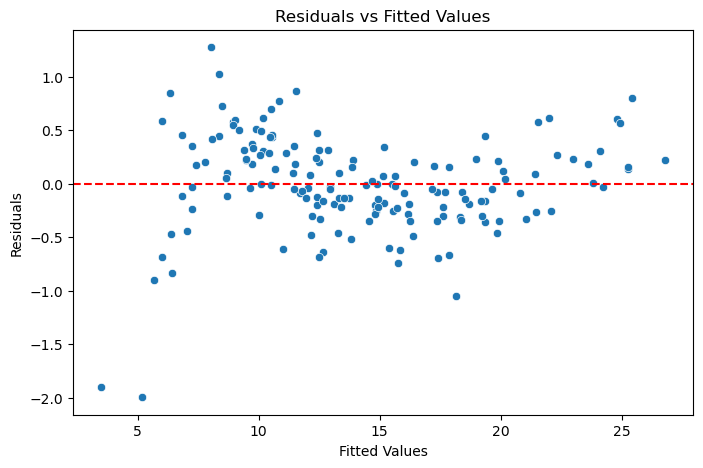

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["predicted_sales"],
    y=df["residuals"]
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.show()

## 5. Scale-Location Plot

The Scale-Location plot is used to assess whether the residual variance remains approximately constant across fitted values.

It plots the square root of the absolute standardized residuals against the fitted values.

A well-behaved plot should ideally show:

- A relatively horizontal trend.
- Similar vertical spread across fitted values.
- No clear increasing or decreasing pattern.

An upward or downward trend may indicate heteroscedasticity.

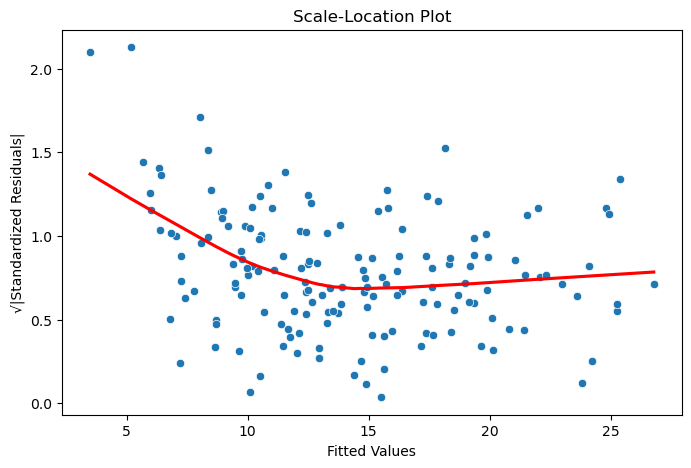

In [8]:
# Calculate standardized residuals
influence = model_d.get_influence()

standardized_residuals = influence.resid_studentized_internal

# Scale-Location plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=model_d.fittedvalues,
    y=np.sqrt(np.abs(standardized_residuals))
)

sns.regplot(
    x=model_d.fittedvalues,
    y=np.sqrt(np.abs(standardized_residuals)),
    scatter=False,
    lowess=True,
    color="red"
)

plt.title("Scale-Location Plot")
plt.xlabel("Fitted Values")
plt.ylabel("√|Standardized Residuals|")

plt.show()

## 6. Influential Observation Analysis Using Cook's Distance

Cook's Distance measures how strongly an individual observation influences the fitted regression model.

An observation with a high Cook's Distance may have a substantial impact on the estimated regression coefficients and overall model fit.

We will use Cook's Distance to identify potentially influential observations.

A commonly used screening threshold is:

Cook's Distance > 4/n

where n represents the number of training observations.

Observations exceeding this threshold will be investigated rather than automatically removed.

In [9]:
# Calculate influence statistics
influence = model_d.get_influence()

# Extract Cook's Distance
cooks_distance = influence.cooks_distance[0]

# Create a results dataframe
cook_df = df.copy()

cook_df["cooks_distance"] = cooks_distance

# Calculate screening threshold
threshold = 4 / len(df)

# Identify potentially influential observations
influential_points = cook_df[
    cook_df["cooks_distance"] > threshold
]

print("Cook's Distance Threshold:", round(threshold, 4))

print(
    "Number of potentially influential observations:",
    len(influential_points)
)

Cook's Distance Threshold: 0.025
Number of potentially influential observations: 12


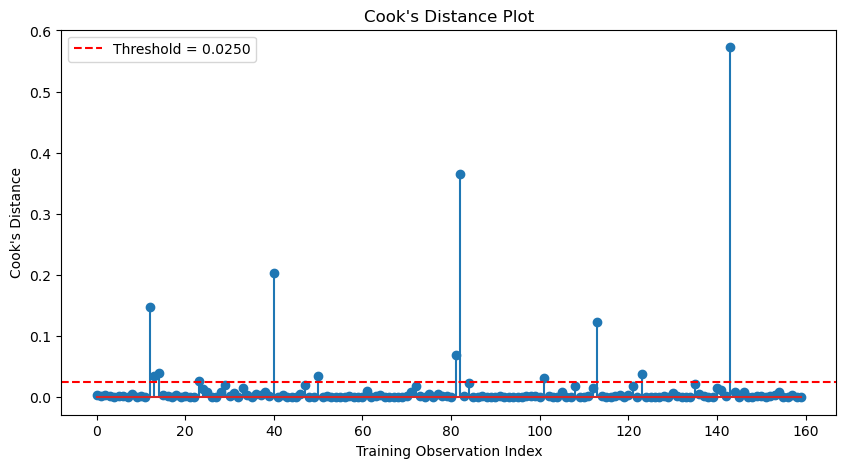

In [10]:
plt.figure(figsize=(10, 5))

plt.stem(
    range(len(cooks_distance)),
    cooks_distance
)

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {threshold:.4f}"
)

plt.title("Cook's Distance Plot")
plt.xlabel("Training Observation Index")
plt.ylabel("Cook's Distance")
plt.legend()

plt.show()

In [11]:
influential_points[
    ["tv", "radio", "newspaper", "sales", "cooks_distance"]
].sort_values(
    by="cooks_distance",
    ascending=False
).round(4)

,tv,radio,newspaper,sales,cooks_distance
131,0.7,39.6,8.7,1.6,0.5726
156,4.1,11.6,5.7,3.2,0.3654
3,17.2,45.9,69.3,9.3,0.2038
6,8.7,48.9,75.0,7.2,0.1480
9,8.6,2.1,1.0,4.8,0.1235
109,13.1,0.4,25.6,5.3,0.0694
118,76.4,0.8,14.8,9.4,0.0392
184,287.6,43.0,71.8,26.2,0.0385
23,13.2,15.9,49.6,5.6,0.0344
127,7.8,38.9,50.6,6.6,0.0344


### Cook's Distance — Key Findings

1. Cook's Distance was calculated for all 160 training observations.
2. Using the screening threshold of 4/n (0.025), 12 observations were identified as potentially influential.
3. Observation 131 recorded the highest Cook's Distance of 0.5726 (TV spend of 0.7), followed by observation 156 with 0.3654 (TV spend of 4.1). Both are ultra-low TV spend observations, which helps explain the negative left tail seen in the Q-Q plot.
4. These observations were investigated because of their potential influence on the fitted regression model.

### Conclusion

The analysis identified several observations that may influence the regression estimates.

However, a high Cook's Distance does not necessarily indicate a data error. Therefore, no observations were removed solely based on this diagnostic, and all training observations were retained for the final model evaluation.

## 7. Final Model Evaluation on Test Data

After completing model selection, statistical testing, and diagnostic checks, the selected Nonlinear TV + Interaction Model will be evaluated on the unseen test dataset.

The test dataset contains observations that were not used during model training or model selection.

The following evaluation metrics will be calculated:

- **R-squared:** Measures the proportion of variation in Sales explained by the model.
- **RMSE:** Measures the typical prediction error, giving greater weight to larger errors.
- **MAE:** Measures the average absolute difference between actual and predicted Sales.

These metrics will help assess the model's predictive performance on unseen data.

In [12]:
# Prepare test data
test_df = df_test.copy()

# Apply training means — do NOT calculate new means from test data
tv_mean = df_train["tv"].apply(np.sqrt).mean()
radio_mean = df_train["radio"].mean()

test_df["sqrt_tv_c"] = np.sqrt(test_df["tv"]) - tv_mean
test_df["radio_c"] = test_df["radio"] - radio_mean

# Fit Model D on the complete training dataset
final_model = smf.ols(
    "sales ~ sqrt_tv_c * radio_c",
    data=df
).fit()

# Predict on unseen test data
y_test = test_df["sales"]
y_pred = final_model.predict(test_df)

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [13]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

test_r2 = r2_score(y_test, y_pred)
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Test R-squared:", round(test_r2, 4))
print("Test MAE:", round(test_mae, 4))
print("Test RMSE:", round(test_rmse, 4))

Test R-squared: 0.9945
Test MAE: 0.3503
Test RMSE: 0.4163


### Final Model Evaluation — Key Findings

1. The selected Nonlinear TV + Interaction Model achieved a test R-squared of 0.9945, explaining approximately 99.45% of the variation in Sales on unseen observations.

2. The model achieved a Mean Absolute Error (MAE) of 0.3503 and a Root Mean Squared Error (RMSE) of 0.4163.

3. Compared with the 5-fold cross-validation results, the model maintained consistent predictive performance on the test dataset.

4. The test RMSE was slightly lower than the cross-validation RMSE, indicating no noticeable deterioration in predictive performance on the held-out observations.

### Conclusion

The Nonlinear TV + Interaction Model demonstrated strong predictive performance on the unseen test dataset.

The results support the model's ability to generalize within this dataset. However, the limited dataset size and observational nature of the data should be considered when interpreting the results.

## 8. Business Scenario Analysis — Advertising Budget Allocation

To demonstrate the practical application of the selected regression model, three hypothetical advertising budget allocations will be compared.

Each scenario uses a total advertising budget of $150,000, distributed differently between TV and Radio.

The selected regression model will predict Sales for each allocation.

This analysis provides an exploratory comparison of predicted Sales under different advertising expenditure combinations.

**Note:** These predictions are based on observational data and should not be interpreted as causal estimates or proven optimal budget allocations. The model does not establish that changing advertising expenditure will cause the predicted change in Sales.

In [14]:
scenarios = pd.DataFrame({
    "Strategy": [
        "TV-focused",
        "Balanced",
        "Radio-focused"
    ],
    "tv": [130.0, 110.0, 101.0],
    "radio": [20.0, 40.0, 49.0]
})

In [15]:
# Apply the same transformations used during training
scenarios["sqrt_tv_c"] = (
    np.sqrt(scenarios["tv"]) - tv_mean
)

scenarios["radio_c"] = (
    scenarios["radio"] - radio_mean
)

# Predict Sales
scenarios["predicted_sales"] = (
    final_model.predict(scenarios).round(2)
)

display(
    scenarios[
        ["Strategy", "tv", "radio", "predicted_sales"]
    ]
)

,Strategy,tv,radio,predicted_sales
0,TV-focused,130.0,20.0,13.34
1,Balanced,110.0,40.0,16.04
2,Radio-focused,101.0,49.0,16.96


### Business Scenario Analysis – Interpretation

The scenario analysis indicates that, for the same hypothetical advertising budget of $150,000, the Radio-focused strategy produces the highest predicted Sales (16.96 thousand units), followed by the Balanced strategy (16.04 thousand units) and the TV-focused strategy (13.34 thousand units).

This suggests that budget allocations involving higher Radio expenditure are associated with higher predicted Sales in the fitted model.

However, these results are exploratory predictions based on historical observational data. They do not establish that reallocating the advertising budget towards Radio will directly cause Sales to increase. Further validation using real-world campaign data would be required before making actual budget allocation decisions.